# Part 2 — Portfolio allocation: regimes versus classical Markowitz
**Ons Jdey & Senghak Rou | Price-only research, no news analysis**

We compare equal weight, classical mean–variance Markowitz, K-Means-conditioned Markowitz, and GMM-conditioned Markowitz. This notebook is standalone; run it after extracting the ZIP. Tables and plots are already executed.

**Research status:** an illustrative portfolio of World Bank monthly-average price-change proxies. It is not an investable futures/ETF total-return backtest. Missing roll yield, collateral, execution prices and historical publication vintages prevent a tradable performance claim.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
BASE=Path.cwd()
if not (BASE/'data').exists(): BASE=BASE/'commodity_regimes'
OUT=BASE/'results/portfolios'; OUT.mkdir(parents=True,exist_ok=True)
SEED=42
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
def plot_save(name):
    plt.tight_layout(); plt.savefig(OUT/name,dpi=150,bbox_inches='tight'); plt.show()
prices=pd.read_csv(BASE/'data/processed/prices_2000_2025.csv',index_col='date',parse_dates=True)
ret=prices.pct_change(fill_method=None).dropna()
lr=np.log(prices).diff().dropna()
X=pd.concat({'r1':lr,'mom3':lr.rolling(3).sum(),
             'vol12':lr.rolling(12).std()*np.sqrt(12)},axis=1).dropna()
X.columns=['__'.join(c) for c in X.columns]
print('Data:',prices.shape,'| Features:',X.shape)

Data: (312, 5) | Features: (300, 15)


## 1. Predeclared protocol and timing
All choices below are fixed before portfolio test evaluation, without searching for the best test Sharpe. The cluster counts (3 for K-Means, 4 for GMM) are taken from Part 1's pre-2021 selection.

For a price-change proxy labeled month $t$, the signal uses features dated **$t-2$**. The allocation history also stops at $t-2$. Thus a January monthly-average observation is assumed available before the start of March. This conservative synthetic publication lag does not replace a true point-in-time vintage database.

Models and scalers are fitted once using observations through December 2020, then frozen. March 2021 is the first test outcome so every signal is later than the model-fitting end. All strategies use exactly March 2021–December 2025 (58 observations).

- Long only, fully invested, maximum weight 60% per asset.
- Monthly rebalancing; risk aversion $\gamma=5$.
- Last 120 available monthly returns for parameter estimation.
- Covariance: 20% shrinkage to its diagonal; means: 50% shrinkage to zero.
- Fee: 10 bp per dollar of absolute traded notional, also tested at 0 and 25 bp.
- No leverage, cash allocation, sentiment, or test-based hyperparameter tuning.

In [2]:
LOOKBACK=120; GAMMA=5.0; CAP=.60; COV_SHRINK=.20; MEAN_SHRINK=.50
PRIOR=24; MIN_EFFECTIVE=12; LAG=2; FEE_BPS=10
MODEL_END=pd.Timestamp('2020-12-01')
model_data=X.loc[:MODEL_END]
scaler=StandardScaler().fit(model_data)
km=KMeans(n_clusters=3,n_init=50,random_state=SEED).fit(scaler.transform(model_data))
gmm=GaussianMixture(n_components=4,covariance_type='diag',reg_covar=1e-4,
                    n_init=20,max_iter=500,random_state=SEED).fit(scaler.transform(model_data))
Z=scaler.transform(X)
km_y=km.predict(Z); gm_p=gmm.predict_proba(Z)
km_prob=pd.DataFrame(np.eye(3)[km_y],index=X.index)
gm_prob=pd.DataFrame(gm_p,index=X.index)
test_dates=ret.loc['2021-03':'2025-12'].index
assert len(test_dates)==58 and gmm.converged_
print('Frozen model end:',MODEL_END.date(),'| Test:',test_dates.min().date(),test_dates.max().date())
display(pd.DataFrame({'value':[LOOKBACK,GAMMA,CAP,LAG,FEE_BPS]},
 index=['lookback_months','gamma','weight_cap','publication_lag_months','fee_bps']))

Frozen model end: 2020-12-01 | Test: 2021-03-01 2025-12-01


,value
lookback_months,120.0
gamma,5.0
weight_cap,0.6
publication_lag_months,2.0
fee_bps,10.0


## 2. Classical mean–variance Markowitz
At each decision date, estimate monthly expected returns $\hat\mu$ and covariance $\hat\Sigma$ using the available trailing history. Solve:

$$\max_w\;w^\top\hat\mu-\frac{\gamma}{2}w^\top\hat\Sigma w,
\quad \sum_i w_i=1,\quad 0\leq w_i\leq0.60.$$

This is a risk-aversion form of Markowitz, not an unconstrained maximum-Sharpe optimization. Shrinking the covariance and the noisy sample mean makes the estimates more stable. The same objective and constraints are used for every Markowitz variant.

In [3]:
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w

## 3. Connecting regimes to future outcomes
Clustering current returns and then treating those same returns as predictions would confuse description and forecasting. Instead, historical pairs are:

$$\big(X_s,\ r_{s+2}\big).$$

The two-month offset matches the publication-lag convention. At a decision cutoff $c$, only outcomes already dated at or before $c$ enter estimates. This is stricter than using all returns available in the target month.

K-Means uses one-hot regime assignments. GMM uses historical component probabilities as observation weights and mixes the current state's component forecasts. For each component, condition the future-return sample on the historical state, then blend it toward unconditional moments with strength $n_{eff}/(n_{eff}+24)$. Below 12 effective observations use the unconditional estimate. GMM effective sample size is $(\sum a_i)^2/\sum a_i^2$.

Covariance mixtures include the **between-component mean dispersion**, preserving the law of total covariance. The blend and regularization are identical in spirit across models; scarce states do not trigger unregularized allocations.

In [4]:
def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

## 4. Walk-forward allocations
The market-regime model is frozen, while moment estimates and portfolio weights update monthly using the lagged rolling history. Classical Markowitz uses exactly the same return-history cutoff as its regime counterparts. No state label estimated from the test future enters the conditional pairs.

In [5]:
NAMES=['Equal weight','Markowitz','KMeans Markowitz','GMM Markowitz']
weights={name:[] for name in NAMES};audit=[]
for date in test_dates:
    cutoff=date-pd.DateOffset(months=LAG)
    assert cutoff>MODEL_END and cutoff<date
    history=ret.loc[:cutoff].tail(LOOKBACK)
    assert len(history)==LOOKBACK and history.index.max()==cutoff
    weights['Equal weight'].append(np.repeat(1/ret.shape[1],ret.shape[1]))
    mu,cov=regularize(*raw_moments(history))
    weights['Markowitz'].append(optimize(mu,cov))
    for name,prob in [('KMeans Markowitz',km_prob),('GMM Markowitz',gm_prob)]:
        mu,cov,info=conditional_moments(history,prob,cutoff)
        weights[name].append(optimize(*regularize(mu,cov)))
        audit.append({'outcome_month':date,'signal_cutoff':cutoff,'model':name,**info})
weights={name:pd.DataFrame(a,index=test_dates,columns=ret.columns) for name,a in weights.items()}
audit=pd.DataFrame(audit)
audit.to_csv(OUT/'timing_and_effective_sample_audit.csv',index=False)
for name,w in weights.items():
    assert np.allclose(w.sum(axis=1),1) and w.min().min()>=-1e-8
    w.to_csv(OUT/(name.lower().replace(' ','_')+'_weights.csv'))
display(audit.head())
print('All allocations obey constraints and lag rules.')

All allocations obey constraints and lag rules.


,outcome_month,signal_cutoff,model,effective_current,fallback_components,latest_outcome
0,2021-03-01,2021-01-01,KMeans Markowitz,15.000000,0,2021-01-01
1,2021-03-01,2021-01-01,GMM Markowitz,12.122928,0,2021-01-01
2,2021-04-01,2021-02-01,KMeans Markowitz,15.000000,0,2021-02-01
3,2021-04-01,2021-02-01,GMM Markowitz,13.120419,0,2021-02-01
4,2021-05-01,2021-03-01,KMeans Markowitz,85.000000,0,2021-03-01


## 5. Turnover, weight drift and costs
Before a rebalance, prior holdings drift with asset price changes. Turnover is the **sum of absolute traded weights**, with no factor of one half. A 10% sale followed by a 10% purchase therefore incurs cost on 20% of portfolio notional.

The first allocation starts from cash, so initial turnover is 1. Costs are paid before the proxy return:

$$R^{net}_t=(1-c\,TO_t)(1+w_t^\top r_t)-1.$$

Drifted weights for the following rebalance are $w_{i,t}(1+r_{i,t})/(1+w_t^\top r_t)$. This prevents understating equal-weight turnover as zero.

In [6]:
def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])
paths={name:backtest(w,FEE_BPS) for name,w in weights.items()}
net=pd.DataFrame({name:p.net_return for name,p in paths.items()})
gross=pd.DataFrame({name:p.gross_return for name,p in paths.items()})
wealth=(1+net).cumprod()
# Include initial wealth=1 when calculating drawdowns.
initial=test_dates[0]-pd.DateOffset(months=1)
wealth_with_start=pd.concat([pd.DataFrame(1.,index=[initial],columns=NAMES),wealth])
drawdown=wealth_with_start/wealth_with_start.cummax()-1
net.to_csv(OUT/'monthly_net_proxy_returns.csv')
gross.to_csv(OUT/'monthly_gross_proxy_returns.csv')
wealth.to_csv(OUT/'wealth_indices.csv')
for name,p in paths.items():p.to_csv(OUT/(name.lower().replace(' ','_')+'_backtest.csv'))

## 6. Comparing results
Annualized volatility uses monthly sample standard deviation times $\sqrt{12}$. Sharpe is annualized arithmetic mean divided by annualized volatility, with **risk-free proxy set to zero** for all strategies; this is not a cash-adjusted futures Sharpe. CAGR uses compounded net price-proxy changes. Maximum drawdown includes initial wealth.

A higher test Sharpe is a sample result, not evidence that the model will outperform in future. The test is short and has already been inspected; further iterative tuning would require a new untouched test.

,CAGR,annualized_vol,Sharpe_rf0,max_drawdown,mean_monthly_turnover,positive_month_fraction,total_return
Equal weight,0.1296,0.1736,0.7915,-0.2533,0.0732,0.6207,0.8024
Markowitz,0.1369,0.1187,1.1448,-0.1707,0.0612,0.6552,0.8591
KMeans Markowitz,0.1356,0.1296,1.0506,-0.1641,0.1726,0.6379,0.8492
GMM Markowitz,0.1410,0.1254,1.1183,-0.2208,0.1865,0.6552,0.8915


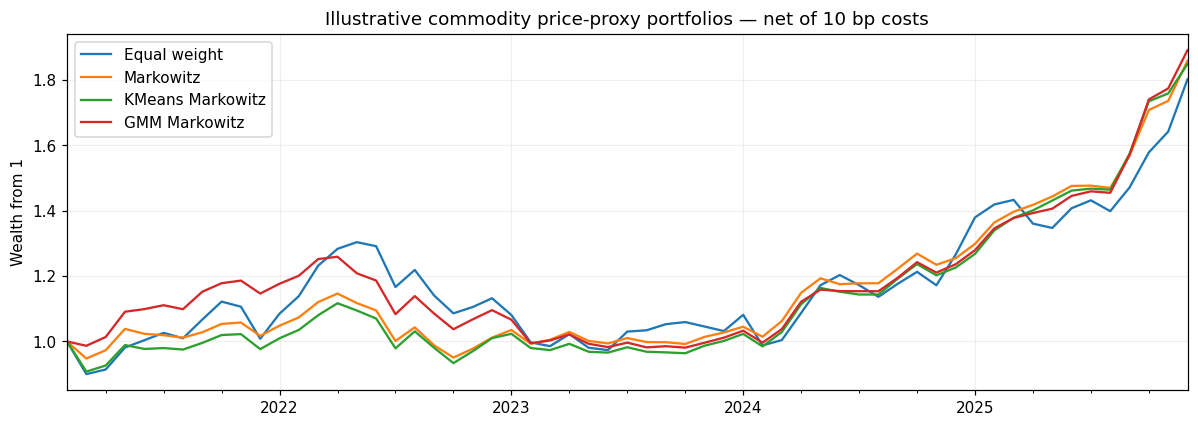

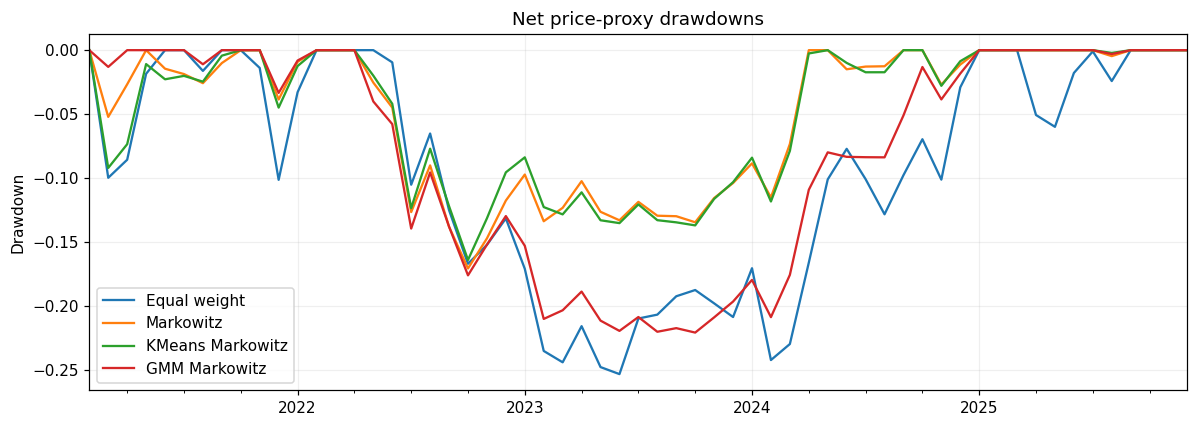

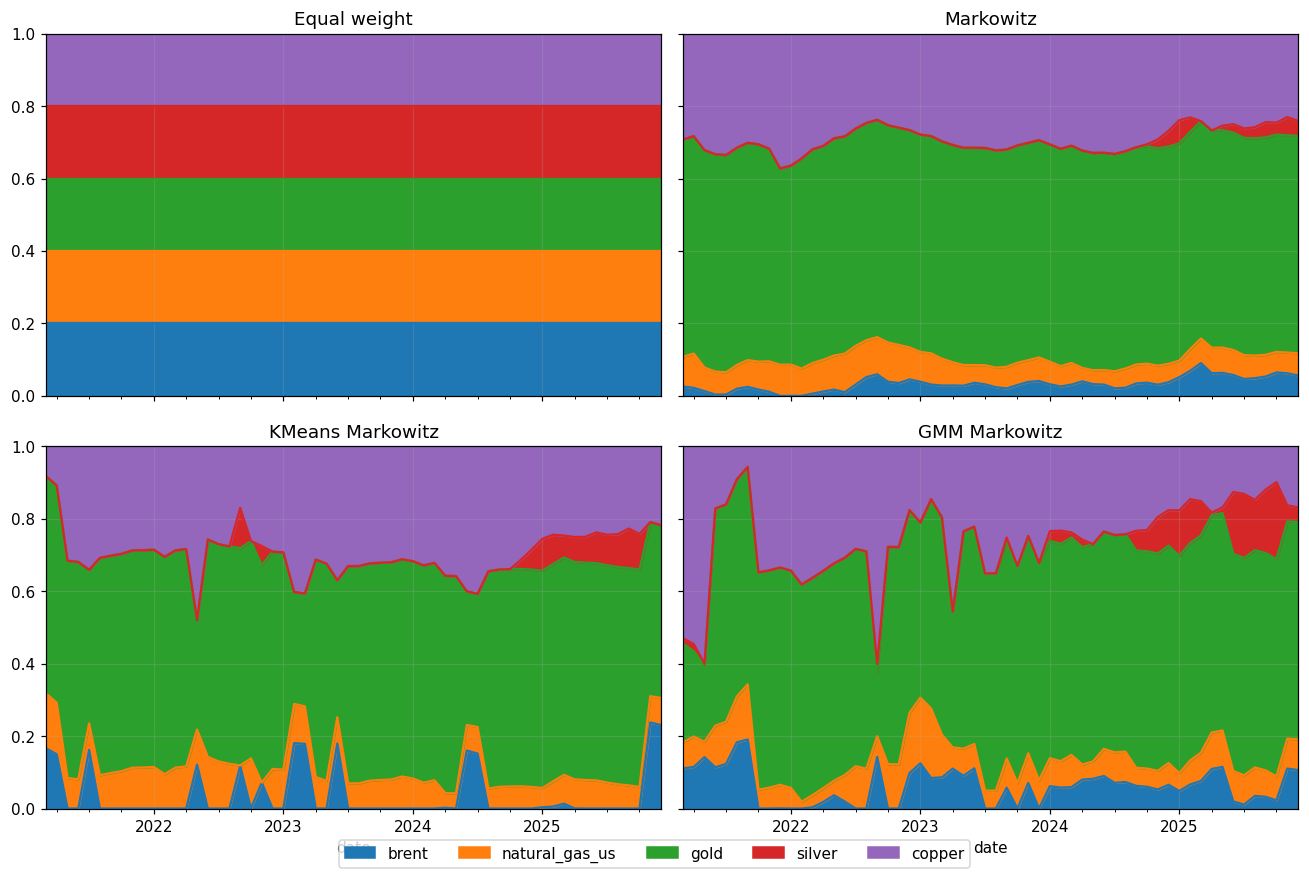

In [7]:
def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})
summary=pd.DataFrame({name:metrics(net[name],paths[name].turnover) for name in NAMES}).T
summary.to_csv(OUT/'performance_summary.csv')
display(summary.round(4))
wealth_with_start.plot(title='Illustrative commodity price-proxy portfolios — net of 10 bp costs')
plt.ylabel('Wealth from 1');plot_save('01_portfolio_wealth.png')
drawdown.plot(title='Net price-proxy drawdowns');plt.ylabel('Drawdown');plot_save('02_drawdowns.png')
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,name in zip(axes.flat,NAMES):
    weights[name].plot.area(ax=ax,ylim=(0,1),title=name,legend=False)
handles,legend_labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,legend_labels,loc='lower center',ncol=5)
fig.subplots_adjust(bottom=.14)
plot_save('03_portfolio_weights.png')

## 7. Transaction-cost sensitivity
The same already-computed target weights are evaluated at 0, 10 and 25 bp; this is sensitivity analysis, not a search to select costs. Costs are not optimized inside the allocation objective.

In [8]:
sensitivity=[]
for fee in [0,10,25]:
    for name,w in weights.items():
        bt=backtest(w,fee)
        m=metrics(bt.net_return,bt.turnover).to_dict()
        sensitivity.append({'fee_bps':fee,'strategy':name,**m})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/'cost_sensitivity.csv',index=False)
display(sensitivity.pivot(index='strategy',columns='fee_bps',values='Sharpe_rf0').round(3))
# Cost, budget, feasibility and indexing checks; no silent optimization failures.
for name in NAMES:
    assert net[name].index.equals(test_dates)
    assert np.isfinite(net[name]).all()
    assert (net[name]<=gross[name]+1e-12).all()
    assert abs(paths[name].turnover.iloc[0]-1)<1e-8
    assert np.allclose(backtest(weights[name],0).net_return,gross[name])
    assert (backtest(weights[name],25).net_return<=paths[name].net_return+1e-12).all()
print('Verified: budgets, caps, chronological cutoffs, initial costs, cost monotonicity and aligned test dates.')

Verified: budgets, caps, chronological cutoffs, initial costs, cost monotonicity and aligned test dates.


fee_bps,0,10,25
strategy,,,
Equal weight,0.797,0.792,0.783
GMM Markowitz,1.138,1.118,1.089
KMeans Markowitz,1.069,1.051,1.023
Markowitz,1.152,1.145,1.134


## 8. Paired uncertainty diagnostic
A circular block bootstrap resamples the same six-month blocks jointly for all strategies, retaining some serial dependence and pairing. This gives a rough 95% interval for the difference in Sharpe versus Markowitz. It does not rerun estimation, account for research selection, or establish causal value. Overlapping features, few observations and the proxy data limit inference.

In [9]:
rng=np.random.default_rng(SEED);n=len(net);B=1000;block=6
bootstrap=[]
def sharpe_array(a):
    sd=np.std(a,axis=0,ddof=1)
    return np.mean(a,axis=0)*np.sqrt(12)/sd
values=net.to_numpy()
for b in range(B):
    starts=rng.integers(0,n,size=int(np.ceil(n/block)))
    ix=np.concatenate([(s+np.arange(block))%n for s in starts])[:n]
    s=sharpe_array(values[ix]);bootstrap.append(s-s[1])
boot=np.array(bootstrap)
uncertainty=pd.DataFrame({'Sharpe_difference_vs_Markowitz':summary.Sharpe_rf0-summary.loc['Markowitz','Sharpe_rf0'],
 'bootstrap_2.5pct':np.quantile(boot,.025,axis=0),
 'bootstrap_97.5pct':np.quantile(boot,.975,axis=0)},index=NAMES)
display(uncertainty.round(3))
uncertainty.to_csv(OUT/'paired_block_bootstrap.csv')

,Sharpe_difference_vs_Markowitz,bootstrap_2.5pct,bootstrap_97.5pct
Equal weight,-0.353,-1.087,0.312
Markowitz,0.000,0.000,0.000
KMeans Markowitz,-0.094,-0.399,0.146
GMM Markowitz,-0.026,-0.554,0.522


## 9. What the comparison answers
This experiment tests whether lagged price-based regimes modify an otherwise comparable mean–variance allocation in a useful way **within this proxy dataset**. It does not require an improvement: report underperformance if that is observed.

Conditional estimates use fewer effective observations than the unconditional benchmark. Prior blending, mean shrinkage and a weight cap reduce instability, but cannot guarantee predictive information. Changing regime representation, lag assumptions, risk aversion, or data frequency may change the ranking.

For an investment backtest, replace monthly-average price proxies with investable commodity total returns and point-in-time predictors; retain identical timing, constraints and cost accounting across strategies. Add genuine risk parity or minimum variance as extra benchmarks if needed. News sentiment remains outside this package's scope.

## Observed results from this execution

| Strategy | CAGR | Volatility | Sharpe (rf=0) | Max drawdown |
|---|---:|---:|---:|---:|
| Equal weight | 12.96% | 17.36% | 0.79 | -25.33% |
| Markowitz | 13.69% | 11.87% | 1.14 | -17.07% |
| KMeans Markowitz | 13.56% | 12.96% | 1.05 | -16.41% |
| GMM Markowitz | 14.10% | 12.54% | 1.12 | -22.08% |

These are net monthly-average price-proxy results for March 2021–December 2025. KMeans Markowitz has a Sharpe difference of -0.09 versus classical Markowitz in this sample. GMM Markowitz has a Sharpe difference of -0.03 versus classical Markowitz in this sample. The paired bootstrap intervals above help assess uncertainty; no robust investment outperformance claim follows from this short proxy experiment.